# Week 3 – Clustering Notebook
Saurav · dataset: `synthetic-clustering-dataset.csv`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

df = pd.read_csv("synthetic-clustering-dataset.csv")
print(df.shape)
df.head()

(120, 14)


,student_key,course_week,group_code,quiz_completed,quiz_score_pct,task_submitted,submission_delay_minutes,task_attempts,monday_activity_count,recorded_attendance,concept_map_submitted,concept_coverage_pct,artifact_size_kb,previous_task_score_pct
0,SYN001,1,G07,1,98.3,1,6.0,3,29,1,0,NaN,1126.4,75.1
1,SYN001,2,G07,1,94.6,1,7.2,4,36,1,1,81.8,875.0,66.0
2,SYN001,3,G07,1,85.4,1,-11.8,5,35,1,1,90.5,775.5,87.9
3,SYN002,1,G03,1,66.8,1,-27.4,1,24,1,1,57.2,210.3,77.2
4,SYN002,2,G03,1,69.0,0,NaN,0,36,1,1,52.8,190.7,65.0


## 1. Understand the data

In [2]:
print("Students:", df["student_key"].nunique(), " Weeks:", sorted(df["course_week"].unique()))
df.isna().sum()

Students: 40  Weeks: [np.int64(1), np.int64(2), np.int64(3)]


student_key                  0
course_week                  0
group_code                   0
quiz_completed               0
quiz_score_pct              28
task_submitted               0
submission_delay_minutes     6
task_attempts                0
monday_activity_count        0
recorded_attendance          0
concept_map_submitted        0
concept_coverage_pct        17
artifact_size_kb             0
previous_task_score_pct      5
dtype: int64

In [3]:
df.describe().T[["mean", "min", "max"]].round(1)

,mean,min,max
course_week,2.0,1.0,3.0
quiz_completed,0.8,0.0,1.0
quiz_score_pct,72.1,28.9,100.0
task_submitted,1.0,0.0,1.0
submission_delay_minutes,31.8,-90.0,166.2
task_attempts,2.0,0.0,6.0
monday_activity_count,25.1,2.0,40.0
recorded_attendance,1.0,0.0,1.0
concept_map_submitted,0.9,0.0,1.0
concept_coverage_pct,67.0,26.5,100.0


- **One observation** = one student in one course week (40 students × 3 weeks = 120 rows).
- **Useful for similarity:** quiz score, submission delay, task attempts, Monday activity and concept coverage. These describe how the student worked that week.
- **Not used as features:** `student_key` and `group_code` (identifiers), `course_week` (time), the 0/1 flags, `artifact_size_kb` (file size doesn't say much about learning), and `previous_task_score_pct` (an earlier grade that would dominate the result).
- **Identifiers:** `student_key`, `group_code`.
- **Missing values:** yes. The quiz score is missing when the quiz was not completed, the delay is missing when the task was not submitted, and coverage is missing when no concept map was submitted. So missing means "not done", not zero.
- **Scales:** very different. The delay goes from −90 to 166 minutes, but attempts only go from 0 to 6.

## 2. Prepare the features

In [4]:
features = ["quiz_score_pct", "submission_delay_minutes", "task_attempts",
            "monday_activity_count", "concept_coverage_pct"]

X_imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(df[features]), columns=features)
X = StandardScaler().fit_transform(X_imp)

I used the five features listed above. Missing values are filled with the median, and then all features are standardized so that each has mean 0 and standard deviation 1.

## 3. Run k-means

In [5]:
km = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = km.fit_predict(X)
df["cluster"] = labels

print(pd.Series(labels).value_counts().sort_index())
pd.DataFrame(km.cluster_centers_, columns=features).round(2)

0    31
1    35
2    54
Name: count, dtype: int64


,quiz_score_pct,submission_delay_minutes,task_attempts,monday_activity_count,concept_coverage_pct
0,-0.87,0.73,-0.27,-1.04,-0.75
1,-0.23,0.34,1.06,0.33,-0.30
2,0.65,-0.64,-0.53,0.39,0.62


The cluster sizes are 31, 35 and 54. The labels 0, 1 and 2 are just names, not a ranking.

## 4. Describe the clusters

In [6]:
df.groupby("cluster")[features].mean().round(1).assign(size=df["cluster"].value_counts().sort_index())

,quiz_score_pct,submission_delay_minutes,task_attempts,monday_activity_count,concept_coverage_pct,size
cluster,,,,,,
0,50.2,77.3,1.7,16.6,52.0,31
1,67.7,51.3,3.5,27.7,61.7,35
2,84.1,-8.3,1.3,28.2,77.9,54


- **Cluster 0 (31):** lowest quiz score, latest submissions, lowest Monday activity and lowest concept coverage.
- **Cluster 1 (35):** clearly the most task attempts (about 3.5). The other values are near the middle.
- **Cluster 2 (54):** highest quiz score and coverage, submits around the deadline or earlier, and has few attempts.

All five variables matter somewhat, and task attempts is what mainly separates cluster 1. No cluster is very small. Clusters 0 and 2 are easy to describe, while cluster 1 is less clear.

## 5. Visualize

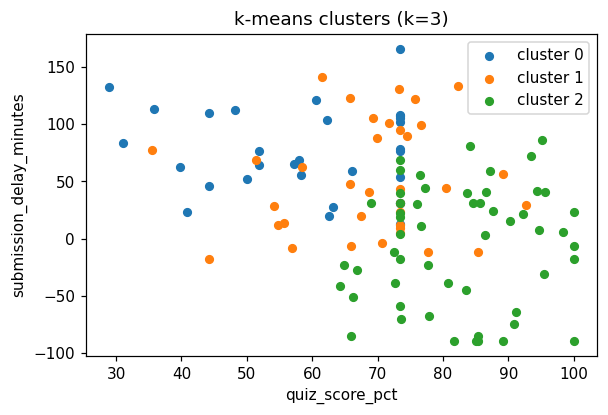

In [7]:
plt.figure(figsize=(6, 3.8))
for c in range(3):
    m = labels == c
    plt.scatter(X_imp.loc[m, "quiz_score_pct"], X_imp.loc[m, "submission_delay_minutes"], label=f"cluster {c}", s=25)
plt.xlabel("quiz_score_pct"); plt.ylabel("submission_delay_minutes")
plt.title("k-means clusters (k=3)"); plt.legend()
plt.show()

The plot shows only two of the five features, so the clusters overlap a bit. Still, cluster 2 is clearly higher on quiz score and lower on delay.

## 6. Compare different numbers of clusters

In [8]:
rows = []
for k in range(2, 7):
    lab = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
    rows.append({"k": k, "silhouette": round(silhouette_score(X, lab), 3),
                 "sizes": sorted(np.bincount(lab), reverse=True)})
pd.DataFrame(rows)

,k,silhouette,sizes
0,2,0.246,"[64, 56]"
1,3,0.214,"[54, 35, 31]"
2,4,0.197,"[37, 31, 26, 26]"
3,5,0.195,"[31, 26, 24, 21, 18]"
4,6,0.197,"[28, 23, 22, 21, 15, 11]"


| k | Main observation |
|---|---|
| 2 | Highest silhouette. It gives a simple split between early / high-score and late / lower-score |
| 3 | Almost as good, and it adds a clear "many attempts" group |
| 4–6 | The silhouette does not improve and the groups get smaller and harder to explain |

All the scores are low (about 0.2), so the clusters are not strongly separated. I chose **k = 3** because it is the easiest to interpret.

## 7. Test the effect of scaling

In [9]:
labels_unscaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_imp)
print("Scaled sizes:  ", np.bincount(labels))
print("Unscaled sizes:", np.bincount(labels_unscaled))
pd.crosstab(labels, labels_unscaled, rownames=["scaled"], colnames=["unscaled"])

Scaled sizes:   [31 35 54]
Unscaled sizes: [37 60 23]


unscaled,0,1,2
scaled,,,
0,19,12,0
1,14,21,0
2,4,27,23


Cluster membership changed a lot. Without scaling, **submission delay** dominates because its values are much larger (tens of minutes) than, for example, attempts (0–6). So the unscaled clusters are basically "early / on time / late" submitters. Scaling makes all features count equally.

## 8. Compare with hierarchical clustering

In [10]:
labels_agg = AgglomerativeClustering(n_clusters=3).fit_predict(X)
print("Agglomerative sizes:", np.bincount(labels_agg))
pd.crosstab(labels, labels_agg, rownames=["k-means"], colnames=["agglomerative"])

Agglomerative sizes: [26 53 41]


agglomerative,0,1,2
k-means,,,
0,22,2,7
1,4,1,30
2,0,50,4


Most observations stay together. The high-score / early group and the many-attempts group mostly match between the two methods. About 18 of 120 observations move, and they are mainly ones with average values that sit between clusters. The groups are about equally easy to interpret with both methods.

## 9. Interpretation and limitations

- **Most useful solution:** k-means with k = 3 on scaled features, because the groups are reasonable in size, easy to describe, and similar to the hierarchical result.
- **Clearly separated?** No. The silhouette is only about 0.2, so the clusters overlap.
- **Another feature selection?** Yes, it could change the groups (for example, adding the previous task score).
- **Another algorithm?** Yes. Hierarchical clustering already moved some observations.
- **Safe to conclude:** in this data, a higher quiz score tends to go with earlier submission and higher coverage, and a separate group has many task attempts.
- **Avoid concluding:** that these are real "types of students", or giving labels like "weak" or "good" students. Rows are student-weeks, the same student can be in different clusters in different weeks, and the dataset is small and synthetic.